## K Nearest Neighbors - KNN

### Import Libraries

In [134]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score


### Read Data

In [105]:
data = pd.read_csv('E:/Machine Learning/Datasets/adult.csv')
data.head()

,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
0,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
1,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
2,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
3,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
4,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,<=50K


In [106]:
data.shape

(32560, 15)

In [107]:
col_names = ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship',
             'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']
data.columns = col_names

data.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education_num',
       'marital_status', 'occupation', 'relationship', 'race', 'sex',
       'capital_gain', 'capital_loss', 'hours_per_week', 'native_country',
       'income'],
      dtype='str')

### EDA

In [108]:
data.isin([' ?']).sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64

In [109]:
data.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
dtype: int64

#### Replace ? With NAN

In [110]:
data['workclass'] = data['workclass'].replace(' ?', np.nan)
data['occupation'] = data['occupation'].replace(' ?', np.nan)
data['native_country'] = data['native_country'].replace(' ?', np.nan)

In [111]:
data.isna().sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64

### Check Missing values

In [112]:
info = pd.DataFrame(data.isnull().sum(),columns=["IsNull"])
info.insert(1,"IsNa",data.isna().sum(),True)
info.insert(2,"Duplicate",data.duplicated().sum(),True)
info.insert(3,"Unique",data.nunique(),True)
info.T

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
IsNull,0,1836,0,0,0,0,1843,0,0,0,0,0,0,583,0
IsNa,0,1836,0,0,0,0,1843,0,0,0,0,0,0,583,0
Duplicate,24,24,24,24,24,24,24,24,24,24,24,24,24,24,24
Unique,73,8,21647,16,16,7,14,6,5,2,119,92,94,41,2


In [113]:
df = data.copy()

#### Remove nan value

In [114]:
df.dropna(how='any', inplace=True)
df

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
1,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
2,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
3,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
4,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32555,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32556,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32557,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32558,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [115]:
df.shape

(30161, 15)

#### Remove Duplicated

In [116]:
df = df.drop_duplicates()

In [117]:
df.shape

(30138, 15)

### remove educational-num, capital-gain, capital-loss


In [118]:
df['education'].unique()

<StringArray>
[   ' Bachelors',      ' HS-grad',         ' 11th',      ' Masters',
          ' 9th', ' Some-college',   ' Assoc-acdm',      ' 7th-8th',
    ' Doctorate',    ' Assoc-voc',  ' Prof-school',      ' 5th-6th',
         ' 10th',    ' Preschool',         ' 12th',      ' 1st-4th']
Length: 16, dtype: str

In [119]:
df['education_num'].unique()

array([13,  9,  7, 14,  5, 10, 12,  4, 16, 11, 15,  3,  6,  1,  8,  2])

#### Drop capital-gain, and capital-loss columns

Text(0.5, 1.0, 'Histogram')

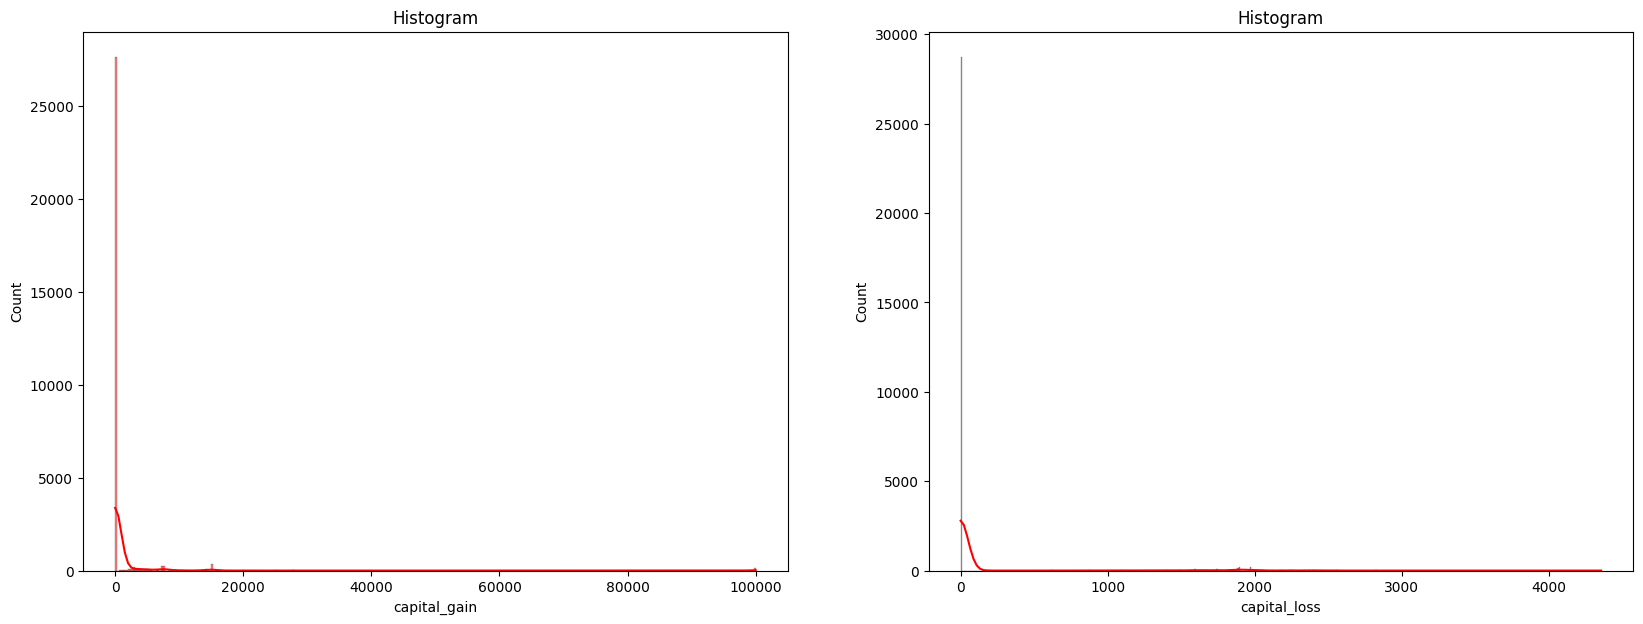

In [120]:
plt.figure(figsize=(20, 7))
plt.subplot(1, 2, 1)
sns.histplot(df['capital_gain'], kde = True,color='r')
plt.title('Histogram')
plt.subplot(1, 2, 2)
sns.histplot(df['capital_loss'], kde = True,color='r')
plt.title('Histogram')

In [121]:
df1 = df.drop(['education_num', 'capital_gain', 'capital_loss'], axis=1)

#### Convert Categorical Cate to Numerical using LableEncoder

In [122]:
df1.info()

<class 'pandas.DataFrame'>
Index: 30138 entries, 0 to 32559
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             30138 non-null  int64
 1   workclass       30138 non-null  str  
 2   fnlwgt          30138 non-null  int64
 3   education       30138 non-null  str  
 4   marital_status  30138 non-null  str  
 5   occupation      30138 non-null  str  
 6   relationship    30138 non-null  str  
 7   race            30138 non-null  str  
 8   sex             30138 non-null  str  
 9   hours_per_week  30138 non-null  int64
 10  native_country  30138 non-null  str  
 11  income          30138 non-null  str  
dtypes: int64(3), str(9)
memory usage: 3.0 MB


In [123]:
df1.head()

,age,workclass,fnlwgt,education,marital_status,occupation,relationship,race,sex,hours_per_week,native_country,income
0,50,Self-emp-not-inc,83311,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,13,United-States,<=50K
1,38,Private,215646,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,40,United-States,<=50K
2,53,Private,234721,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,40,United-States,<=50K
3,28,Private,338409,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,40,Cuba,<=50K
4,37,Private,284582,Masters,Married-civ-spouse,Exec-managerial,Wife,White,Female,40,United-States,<=50K


In [124]:
label_encoder = LabelEncoder()

df1['sex'] = label_encoder.fit_transform(df1['sex'])
df1['workclass'] = label_encoder.fit_transform(df1['workclass'])
df1['education'] = label_encoder.fit_transform(df1['education'])
df1['marital_status'] = label_encoder.fit_transform(df1['marital_status'])
df1['occupation'] = label_encoder.fit_transform(df1['occupation'])
df1['relationship'] = label_encoder.fit_transform(df1['relationship'])
df1['race'] = label_encoder.fit_transform(df1['race'])
df1['native_country'] = label_encoder.fit_transform(df1['native_country'])
df1['income'] = label_encoder.fit_transform(df1['income'])

In [125]:
df1.head()

,age,workclass,fnlwgt,education,marital_status,occupation,relationship,race,sex,hours_per_week,native_country,income
0,50,4,83311,9,2,3,0,4,1,13,38,0
1,38,2,215646,11,0,5,1,4,1,40,38,0
2,53,2,234721,1,2,5,0,2,1,40,38,0
3,28,2,338409,9,2,9,5,2,0,40,4,0
4,37,2,284582,12,2,3,5,4,0,40,38,0


In [126]:
info = pd.DataFrame(df1.isnull().sum(),columns=["IsNull"])
info.insert(1,"IsNa",df1.isna().sum(),True)
info.T

,age,workclass,fnlwgt,education,marital_status,occupation,relationship,race,sex,hours_per_week,native_country,income
IsNull,0,0,0,0,0,0,0,0,0,0,0,0
IsNa,0,0,0,0,0,0,0,0,0,0,0,0


#### Correlation matrix

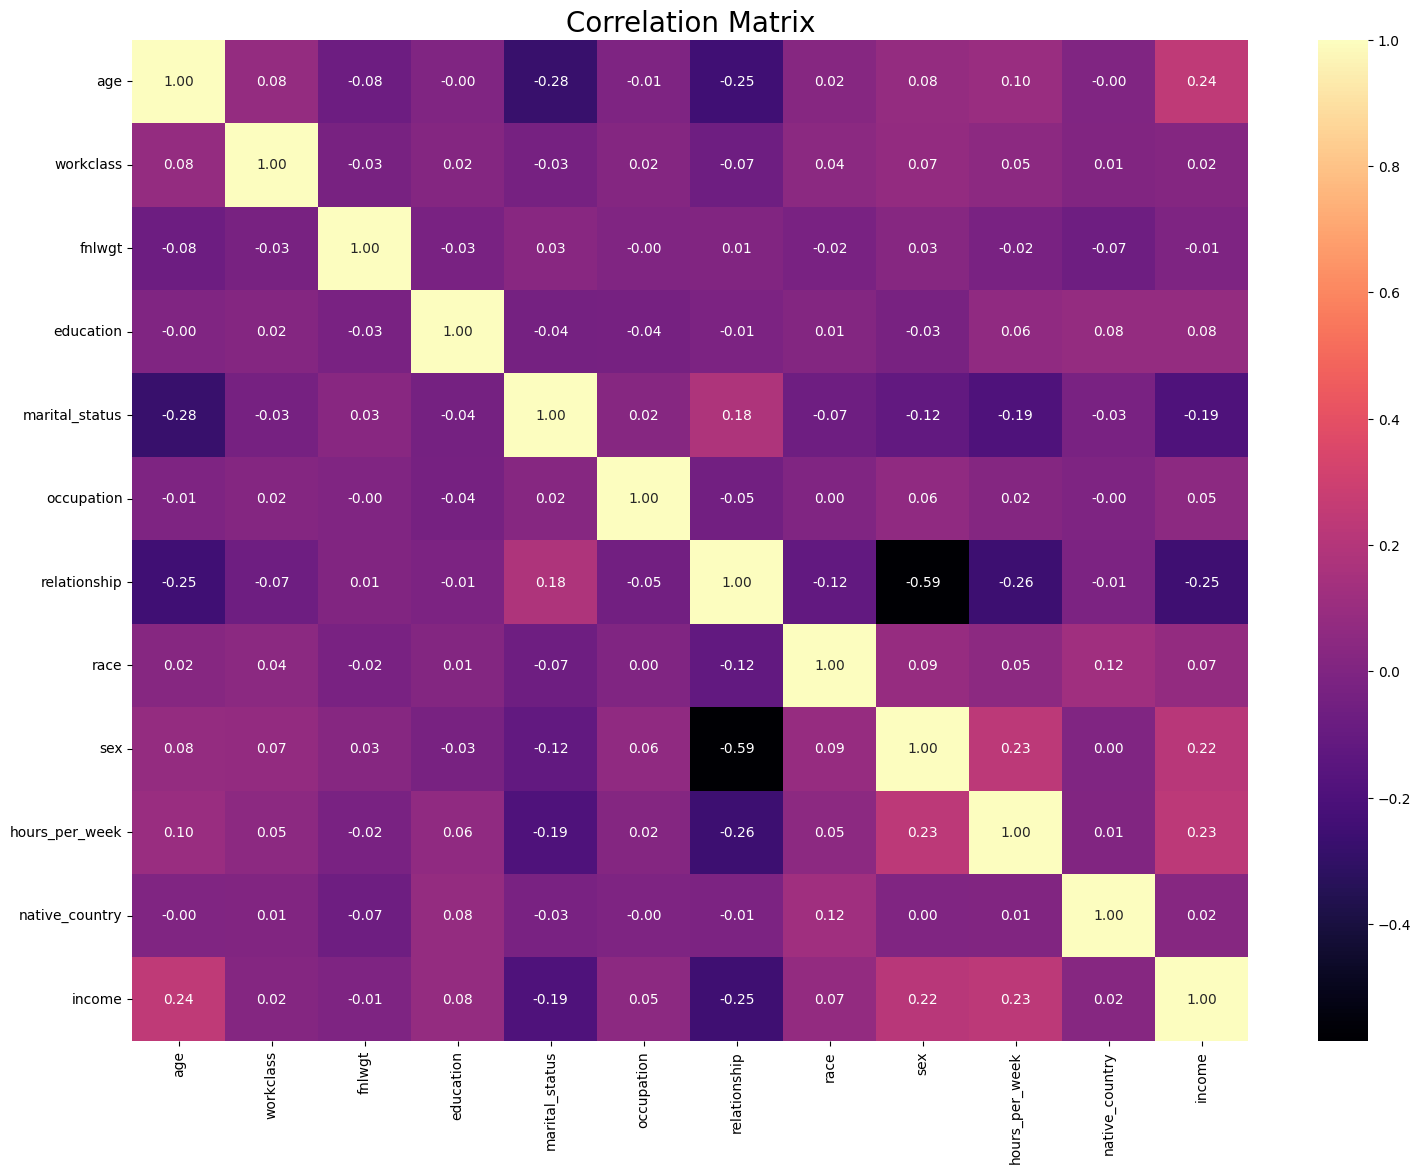

In [127]:
f, ax = plt.subplots(figsize=[18, 13])
sns.heatmap(df1.corr(), annot=True, fmt=".2f", ax=ax, cmap="magma")
ax.set_title("Correlation Matrix", fontsize=20)
plt.show()

In [128]:
def diagnostic_plots(df, variable,target):
    # The function takes a dataframe (df) and
    # the variable of interest as arguments.

    # Define figure size.
    plt.figure(figsize=(20, 7))

    # histogram
    plt.subplot(1, 4, 1)
    sns.histplot(df[variable], kde = True,color='r')
    plt.title('Histogram')


    # scatterplot
    plt.subplot(1, 4, 2)
    plt.scatter(df[variable],df[target],color = 'g')
    plt.title('Scatterplot')


    # boxplot
    plt.subplot(1, 4, 3)
    sns.boxplot(y=df[variable],color = 'b')
    plt.title('Boxplot')

    # barplot
    plt.subplot(1, 4, 4)
    sns.barplot(x = target, y = variable, data = df)
    plt.title('Barplot')


    plt.show()

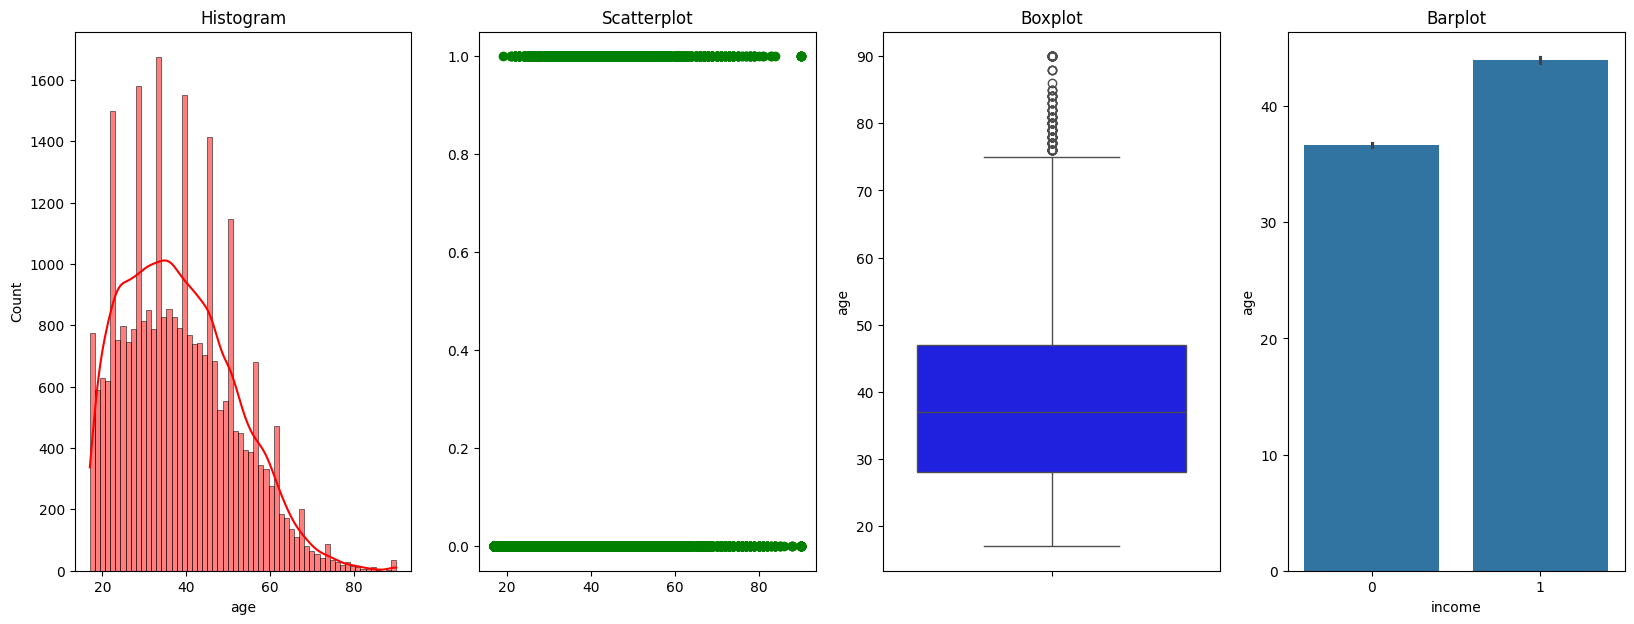

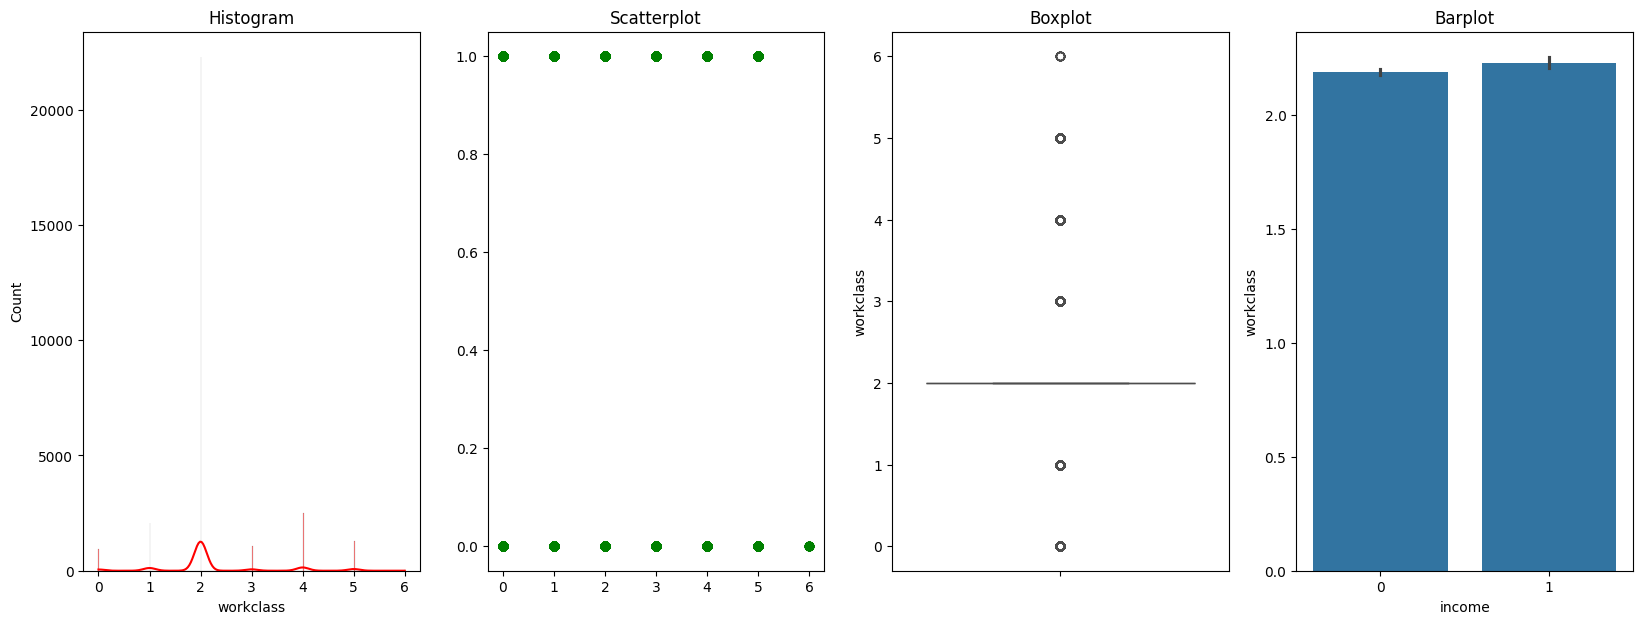

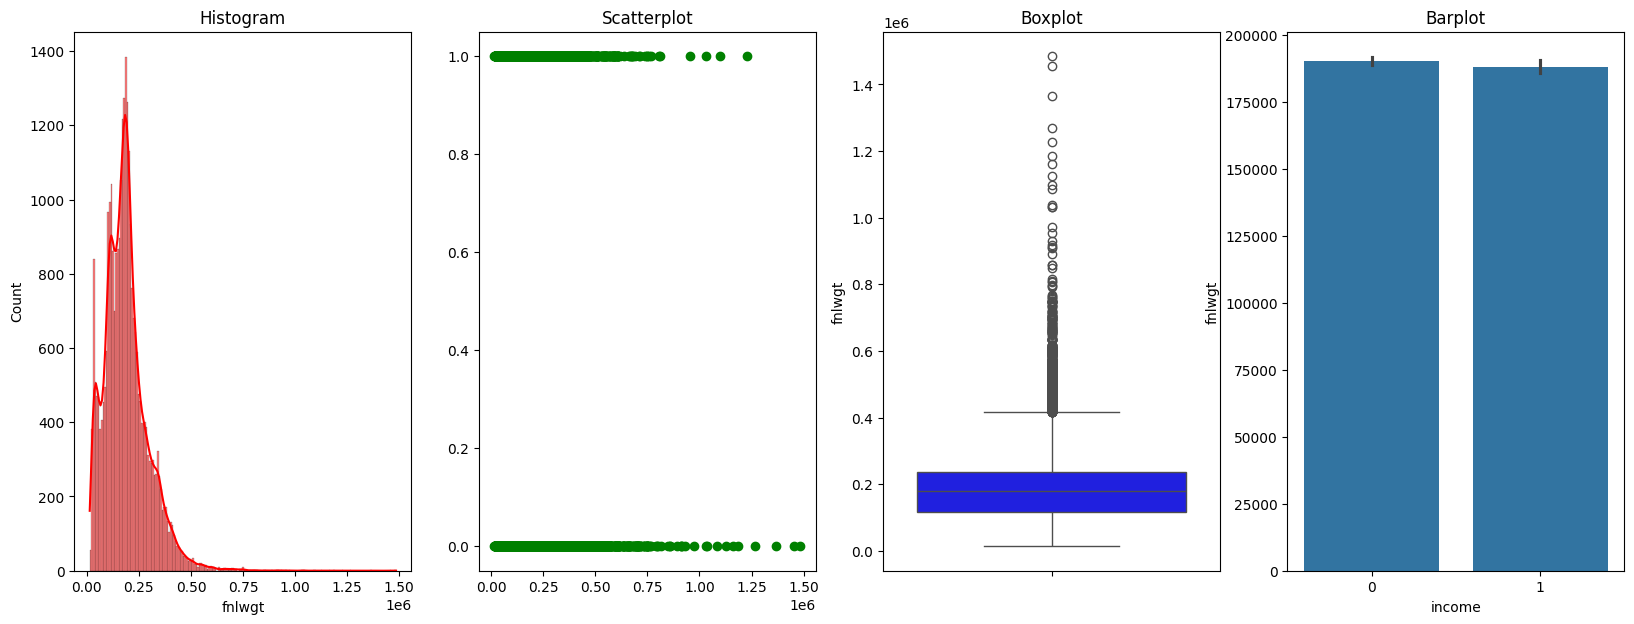

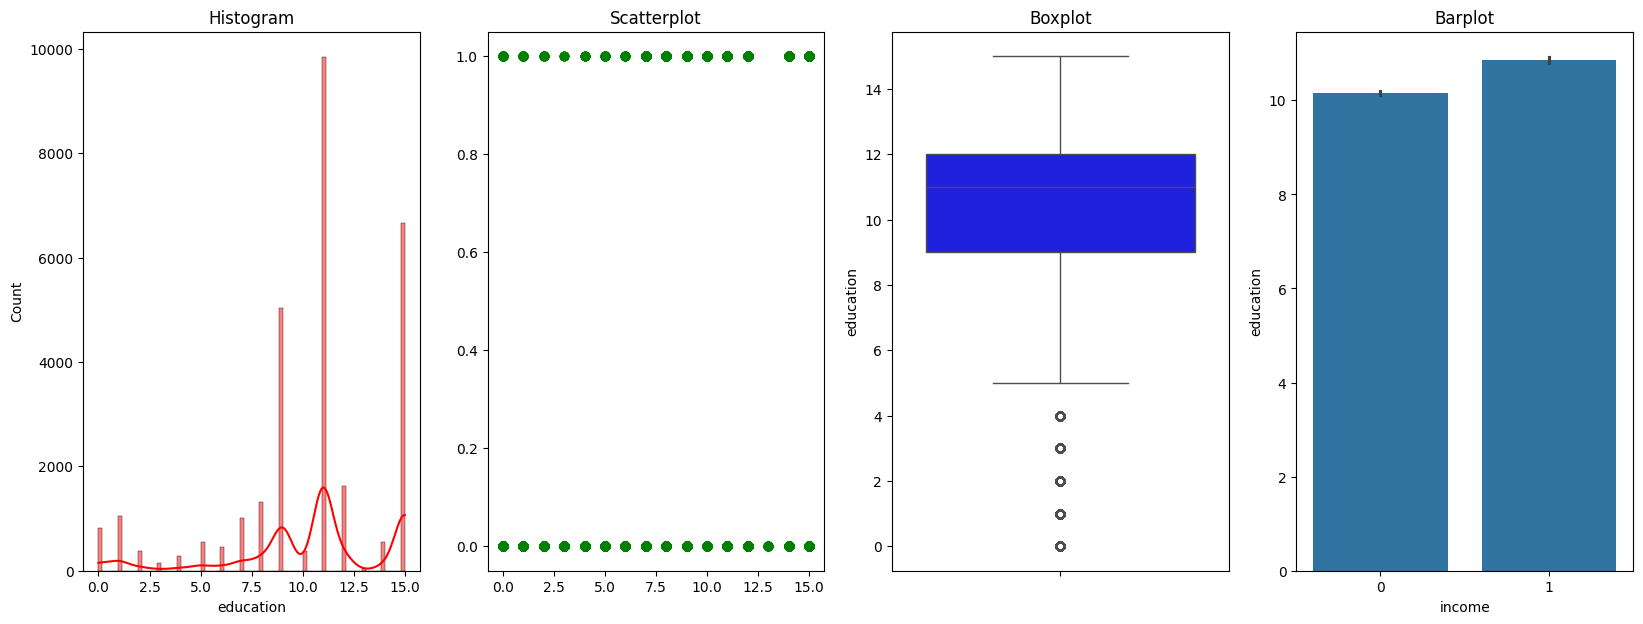

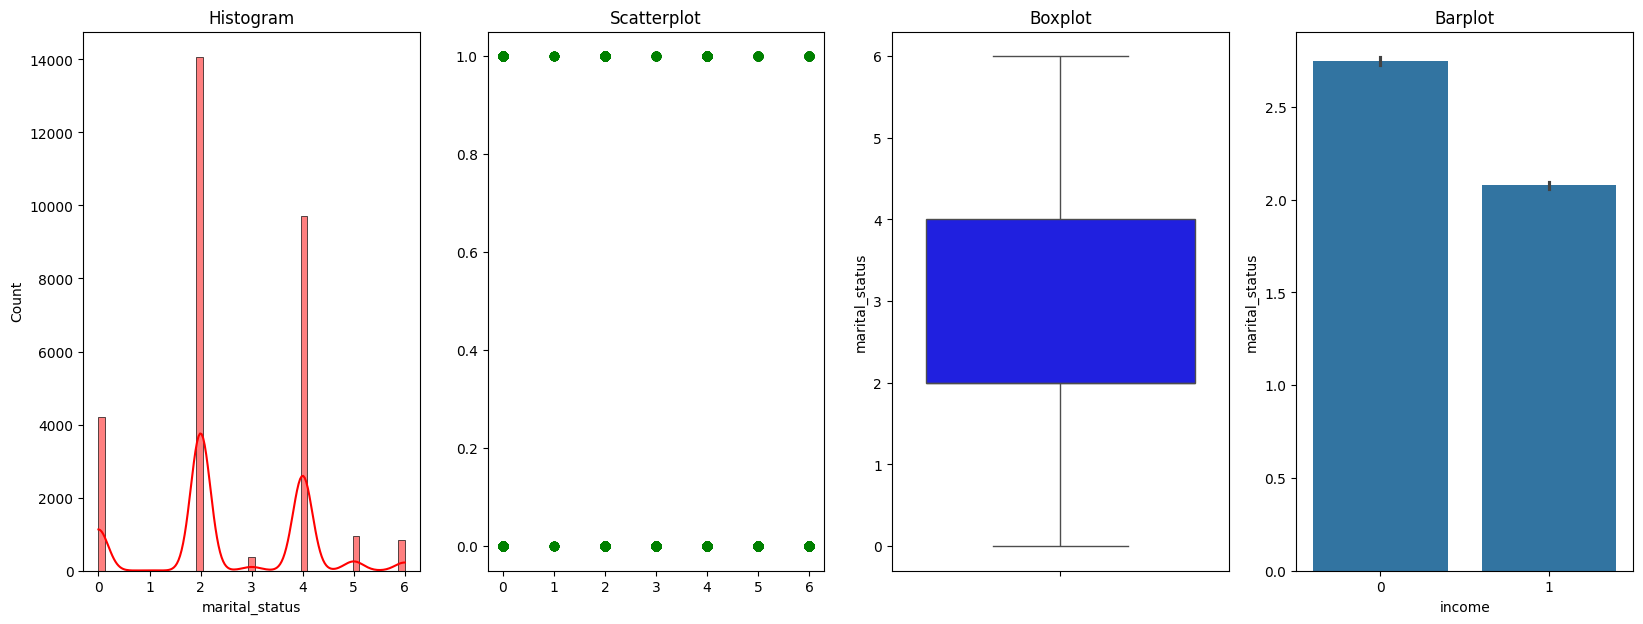

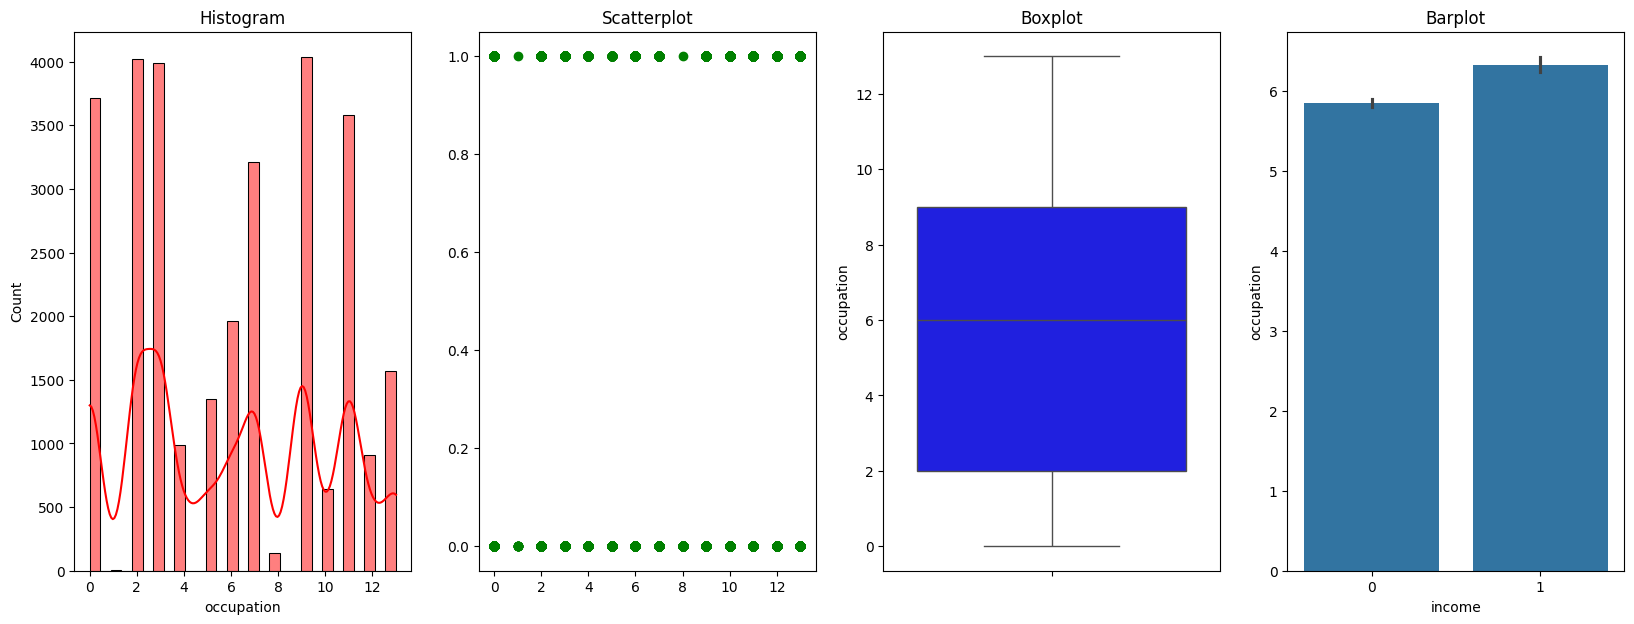

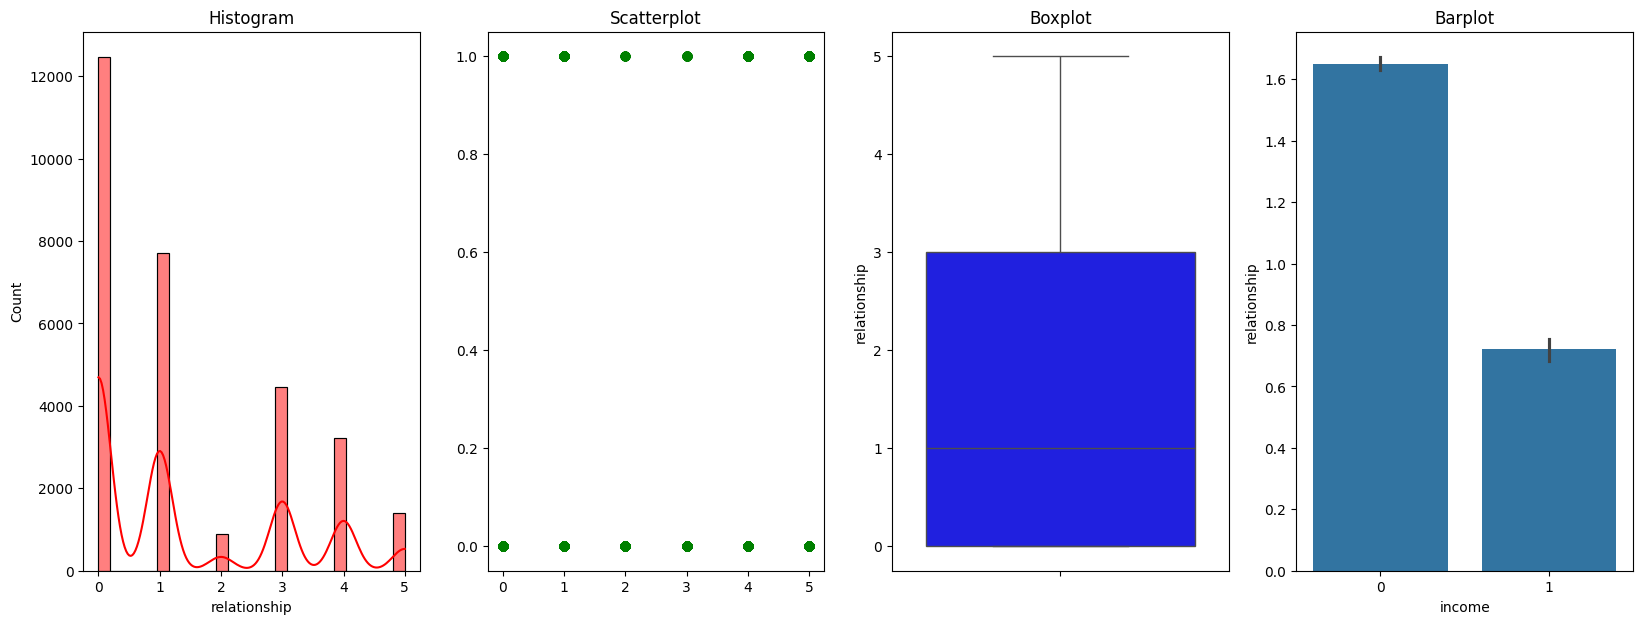

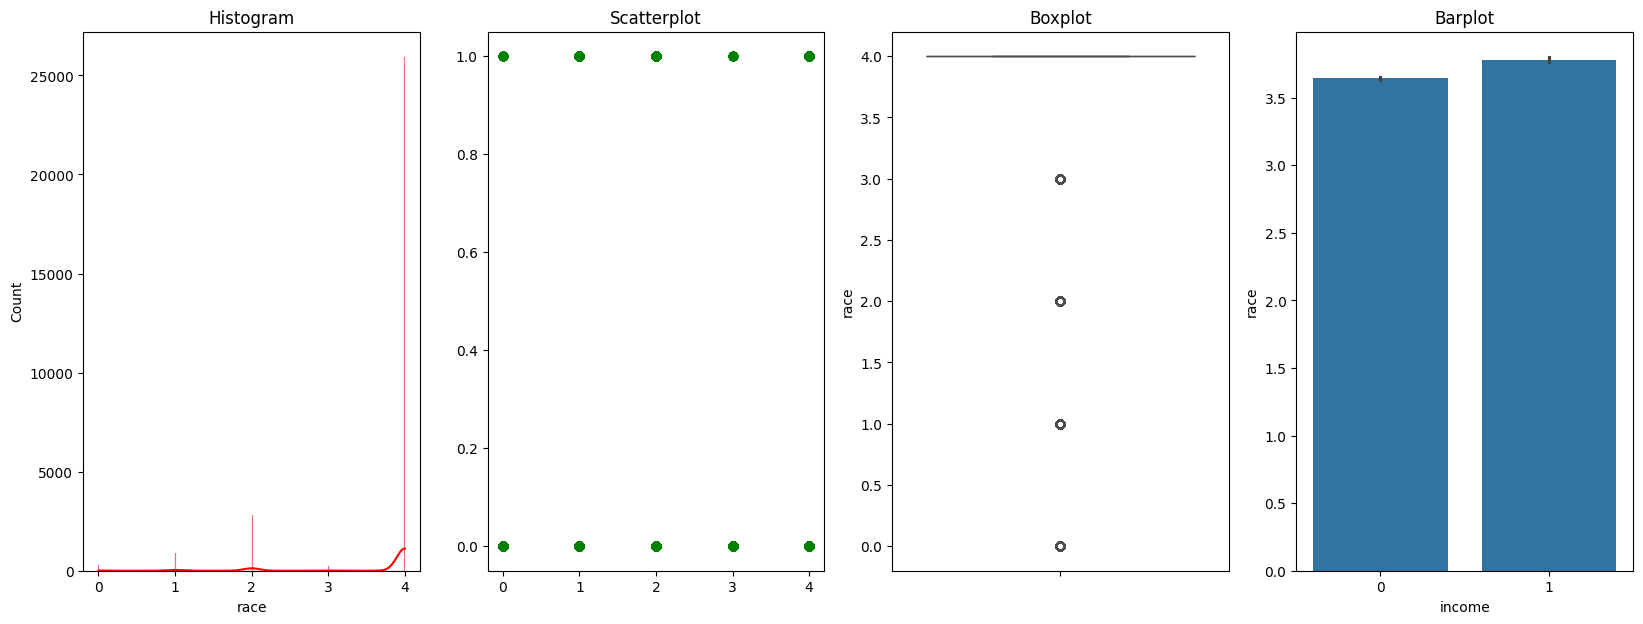

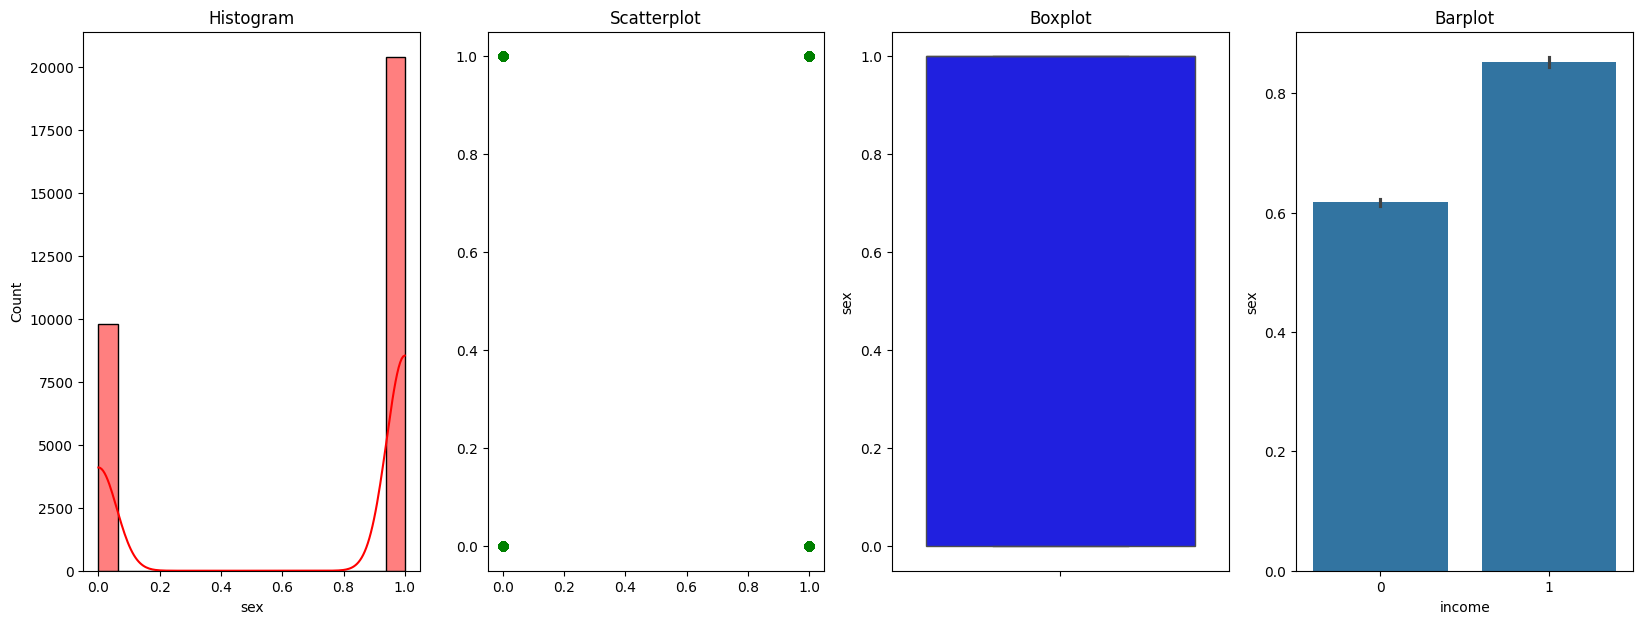

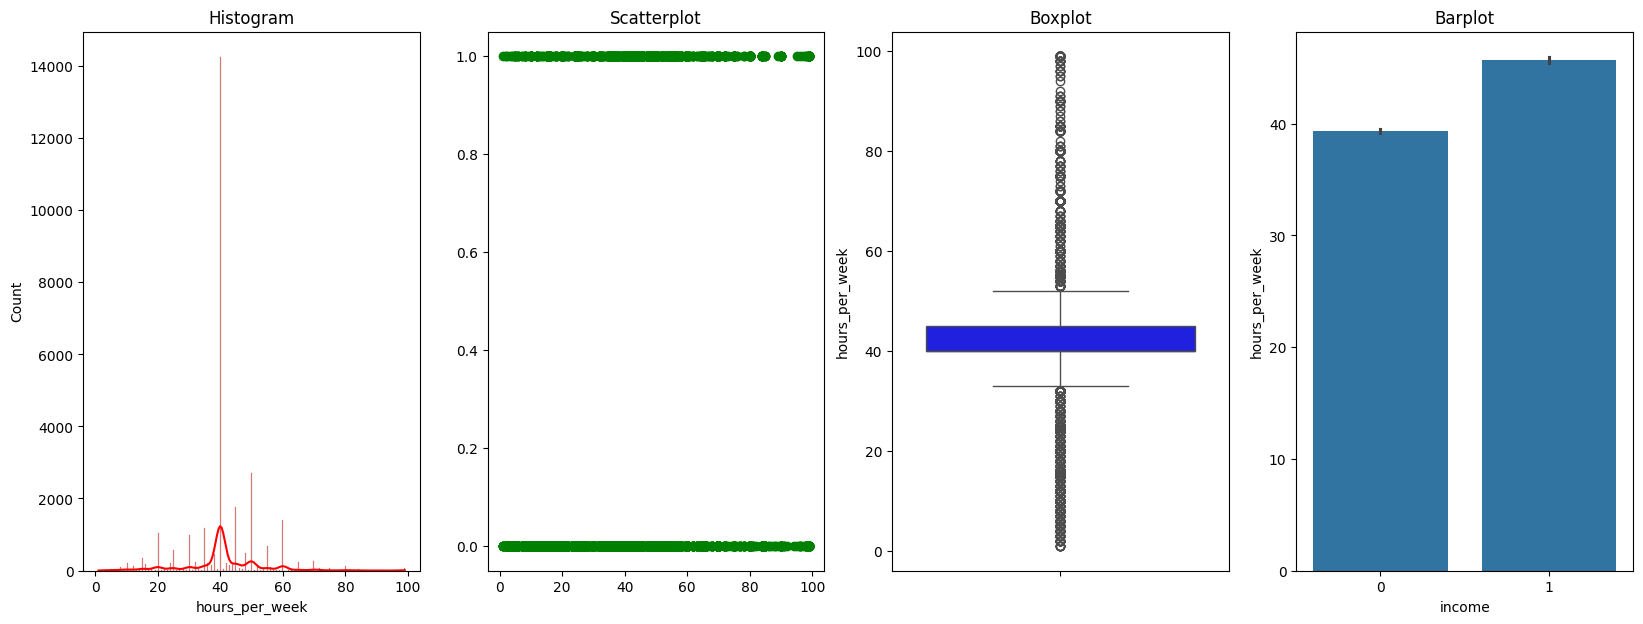

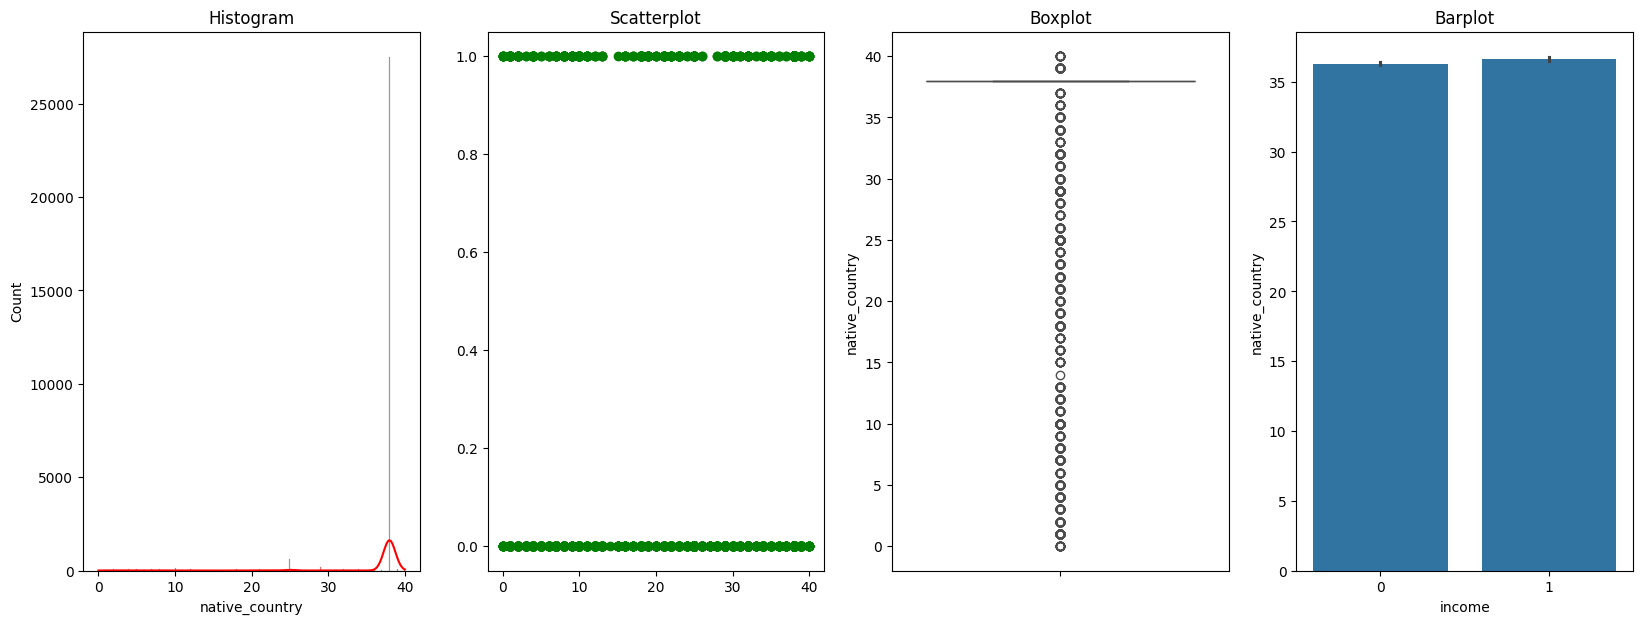

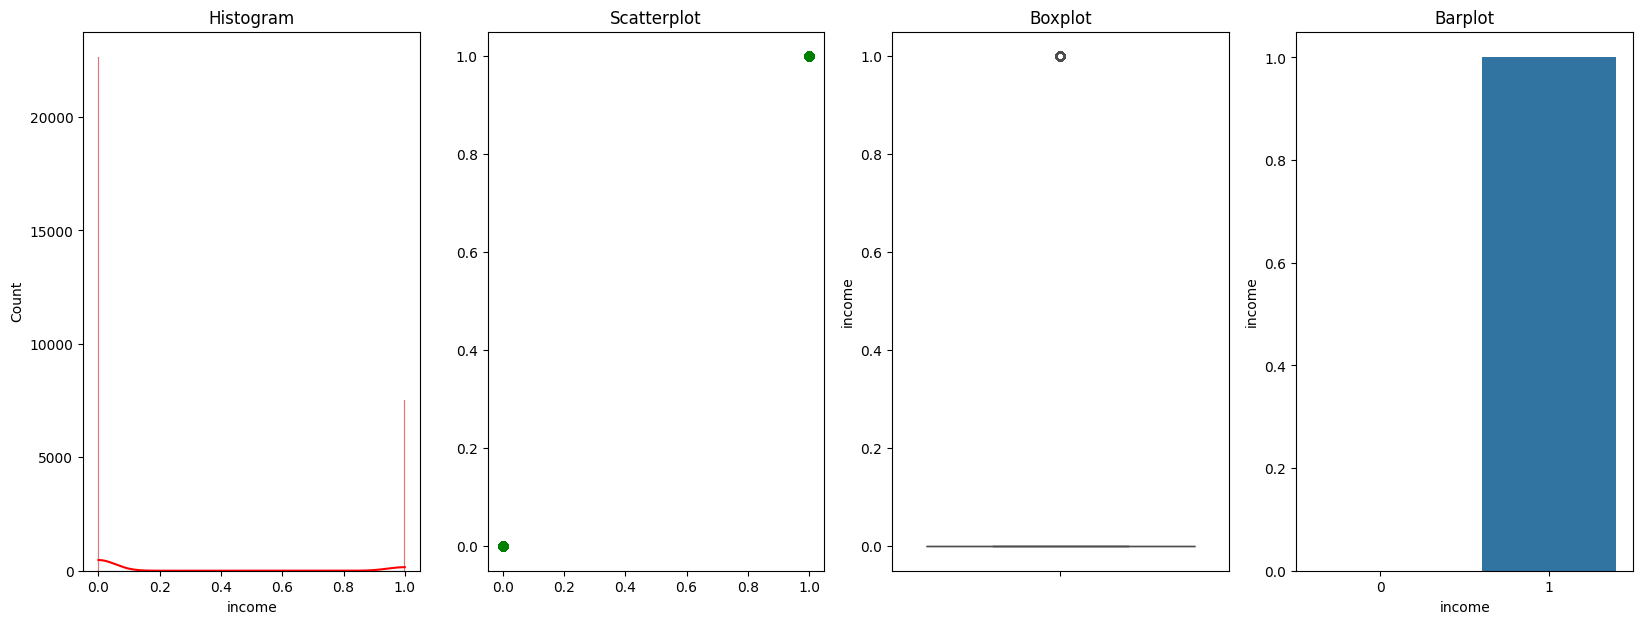

In [129]:
for col in df1:
    diagnostic_plots(df1,col,'income')

### Model

#### Split Data

In [131]:
x = df1.drop('income', axis=1)
y = df1['income'].values.reshape(-1, 1)

In [132]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

x_train shape: (24110, 11)
x_test shape: (6028, 11)
y_train shape: (24110, 1)
y_test shape: (6028, 1)


In [133]:
# Robust Scaling x_train, x_test

robust_scaler = RobustScaler()
x_train = robust_scaler.fit_transform(x_train)
x_test = robust_scaler.transform(x_test)

Scaling Data

In [135]:
st =MinMaxScaler()
X_train = st.fit_transform(x_train)
X_test = st.fit_transform(x_test)

In [136]:
#Find Best K
K = 40
error =[]
accuracy=[]
for i in range(1,K+1):
    knn= KNeighborsClassifier(n_neighbors= i) # n_neighbors = K
    knn.fit(X_train,y_train)
    y_pred =knn.predict(X_test)
    error.append(1-accuracy_score(y_test,y_pred))
    accuracy.append(accuracy_score(y_test,y_pred))


c:\Users\moham\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neighbors\_classification.py:243: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
c:\Users\moham\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neighbors\_classification.py:243: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
c:\Users\moham\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neighbors\_classification.py:243: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
c:\Users\moham\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neighbors\_classification.py:243: 

In [137]:
print(error)
print(accuracy)

[0.23125414731254146, 0.21201061712010616, 0.1972461844724619, 0.1970802919708029, 0.19508958195089587, 0.19077637690776372, 0.19077637690776372, 0.18646317186463168, 0.18613138686131392, 0.18646317186463168, 0.18563370935633705, 0.18546781685467817, 0.18480424684804242, 0.18231585932315864, 0.18231585932315864, 0.18115461181154613, 0.18198407431984076, 0.18314532183145327, 0.18347710683477103, 0.1828135368281354, 0.1851360318513603, 0.18314532183145327, 0.18546781685467817, 0.1853019243530193, 0.1862972793629728, 0.1851360318513603, 0.18696084936960844, 0.1851360318513603, 0.18679495686794956, 0.18463835434638354, 0.18596549435965493, 0.18596549435965493, 0.18646317186463168, 0.18563370935633705, 0.18646317186463168, 0.18613138686131392, 0.18480424684804242, 0.18563370935633705, 0.1862972793629728, 0.18662906436629068]
[0.7687458526874585, 0.7879893828798938, 0.8027538155275381, 0.8029197080291971, 0.8049104180491041, 0.8092236230922363, 0.8092236230922363, 0.8135368281353683, 0.81386

Text(0.5, 1.0, 'accuracy vs K')

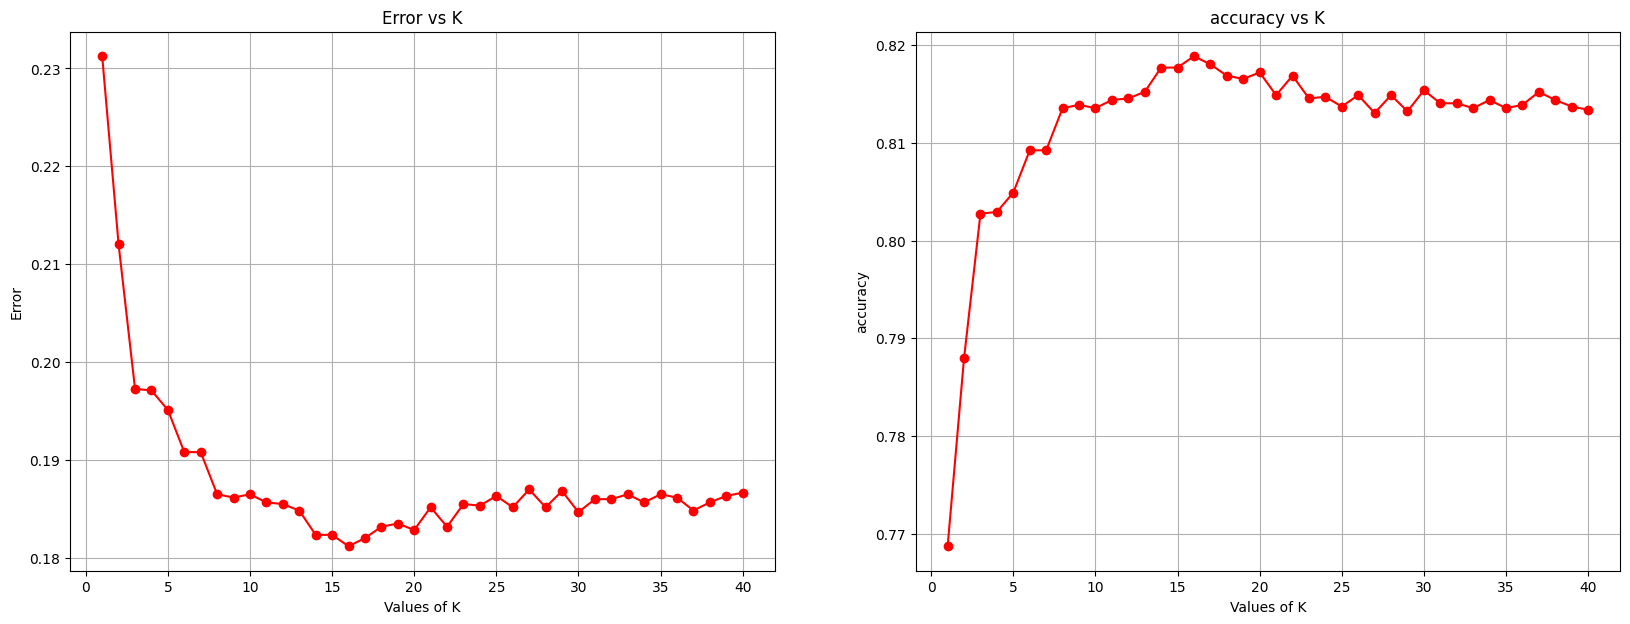

In [138]:

plt.figure(figsize=(20, 7))
plt.subplot(1, 2, 1)
plt.plot(range(1,41),error,'r-',marker='o')
plt.xlabel('Values of K')
plt.ylabel('Error')
plt.grid()
plt.title('Error vs K')

plt.subplot(1, 2, 2)
plt.plot(range(1,41),accuracy,'r-',marker='o')
plt.xlabel('Values of K')
plt.ylabel('accuracy')
plt.grid()
plt.title('accuracy vs K')

In [139]:
K=34
clf= KNeighborsClassifier(K)
clf.fit(x_train,y_train)
y_pred =clf.predict(x_test)
print("Accuracy :" ,accuracy_score(y_test,y_pred))

c:\Users\moham\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neighbors\_classification.py:243: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


Accuracy : 0.803085600530856


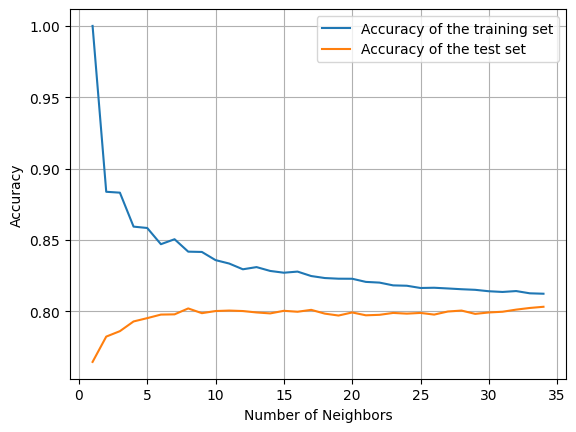

In [140]:
#Find Best K
training_acc = []
test_acc = []

# try KNN for different K nearest neighbor from 1 to 30
neighbors_setting = range(1,35)
for n_neighbors in neighbors_setting:
    knn= KNeighborsClassifier(n_neighbors= n_neighbors, )
    knn.fit(x_train,y_train.ravel())
    training_acc.append(knn.score(x_train,y_train))
    test_acc.append(knn.score(x_test,y_test))

plt.plot(neighbors_setting,training_acc,label='Accuracy of the training set')
plt.plot(neighbors_setting,test_acc,label='Accuracy of the test set')
plt.ylabel('Accuracy')
plt.xlabel('Number of Neighbors')
plt.grid()
plt.legend()
plt.show()

In [141]:
print(training_acc[-1], test_acc[-1])

0.8122355868934052 0.803085600530856


In [142]:
#Find Best K

param_grid = {
    'n_neighbors': [ 7, 9, 11, 13, 15,25, 34],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

grid_kn=GridSearchCV(estimator=knn,#model
                     param_grid=param_grid, #range of K
                    scoring='accuracy',# Strategy to evaluate the performance of the cross-validation model on the test set.
                    cv= 5, # Cross-validation generator
                    verbose= 1, #Time to calculate
                    n_jobs= -1 #Help to cpu
                    )
grid_kn.fit(X_train,y_train.ravel())

Fitting 5 folds for each of 42 candidates, totalling 210 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsCla..._neighbors=34)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'metric': ['euclidean', 'manhattan', ...], 'n_neighbors': [7, 9, ...], 'weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_s

In [143]:
grid_kn.best_params_

{'metric': 'manhattan', 'n_neighbors': 25, 'weights': 'distance'}

In [145]:
best_knn = grid_kn.best_estimator_

# Make predictions on the test set
y_pred_best = best_knn.predict(X_test)

# Evaluate the model
accuracy_best = accuracy_score(y_test, y_pred_best)
print("Accuracy with best K (24):", accuracy_best)


Accuracy with best K (24): 0.8188453881884539


              precision    recall  f1-score   support

           0     0.8621    0.9032    0.8822      4527
           1     0.6591    0.5643    0.6080      1501

    accuracy                         0.8188      6028
   macro avg     0.7606    0.7338    0.7451      6028
weighted avg     0.8116    0.8188    0.8139      6028



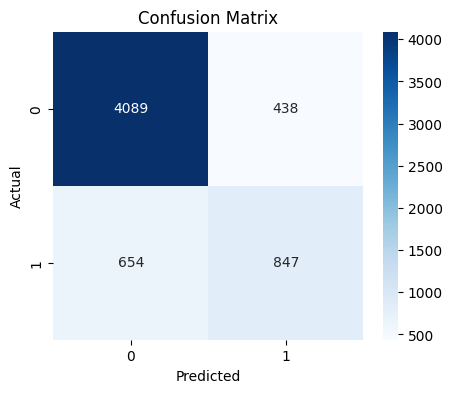

In [146]:
# Classification report
print(classification_report(y_test, y_pred_best, digits=4))

# Confusion matrix with heat map
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()
